# Predicting Student Math Scores
Student ID: leapit6717
Date: October 28, 2026

In [1]:
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_excel("StudentsPerformance.xlsx")

print("Number of students:", len(df))
print(df.head())

Number of students: 1000
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [2]:
categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

encoded_df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

print(encoded_df.head())
print("\nEncoded columns:")
print(encoded_df.columns.tolist())

   math score  reading score  writing score  gender_male  \
0          72             72             74            0   
1          69             90             88            0   
2          90             95             93            0   
3          47             57             44            1   
4          76             78             75            1   

   race/ethnicity_group B  race/ethnicity_group C  race/ethnicity_group D  \
0                       1                       0                       0   
1                       0                       1                       0   
2                       1                       0                       0   
3                       0                       0                       0   
4                       0                       1                       0   

   race/ethnicity_group E  parental level of education_bachelor's degree  \
0                       0                                              1   
1                       

In [3]:
X = encoded_df.drop(columns=["math score"])
y = encoded_df["math score"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 800
Testing students: 200


In [4]:
model = LinearRegression()

model.fit(X_train, y_train)

print("Linear regression model trained successfully.")

Linear regression model trained successfully.


In [5]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
r_squared = r2_score(y_test, predictions)

print(f"MAE: {mae:.3f}")
print(f"MSE: {mse:.3f}")
print(f"R-squared: {r_squared:.3f}")

comparison = pd.DataFrame({
    "Actual Math Score": y_test,
    "Predicted Math Score": predictions
})

print("\nFirst 10 predictions:")
print(comparison.head(10).round(2))

MAE: 4.215
MSE: 29.095
R-squared: 0.880

First 10 predictions:
     Actual Math Score  Predicted Math Score
521                 91                 76.39
737                 53                 58.89
740                 80                 76.99
660                 74                 76.85
411                 84                 87.63
678                 81                 79.01
626                 69                 64.65
513                 54                 53.01
859                 87                 74.18
136                 51                 49.21


In [6]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(coefficients.to_string(index=False))

reading_coefficient = model.coef_[
    X.columns.get_loc("reading score")
]

print(
    "\nPredicted math score change for each additional "
    f"reading point: {reading_coefficient:.3f}"
)

                                      Feature  Coefficient  Absolute Coefficient
                                  gender_male    13.064884             13.064884
                       race/ethnicity_group E     4.892649              4.892649
                               lunch_standard     3.510075              3.510075
                 test preparation course_none     3.289642              3.289642
  parental level of education_master's degree    -1.400489              1.400489
     parental level of education_some college     0.998856              0.998856
      parental level of education_high school     0.929312              0.929312
 parental level of education_some high school     0.756470              0.756470
                                writing score     0.724148              0.724148
parental level of education_bachelor's degree    -0.716901              0.716901
                       race/ethnicity_group C    -0.625617              0.625617
                       race/

# Student Performance Prediction and Interventions
Student ID: leapit6717
Date: November 6, 2026

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

df = pd.read_excel("StudentsPerformance.xlsx")

print("Number of students:", len(df))
print(df.head())

Number of students: 1000
   gender race/ethnicity parental level of education         lunch  \
0  female        group B           bachelor's degree      standard   
1  female        group C                some college      standard   
2  female        group B             master's degree      standard   
3    male        group A          associate's degree  free/reduced   
4    male        group C                some college      standard   

  test preparation course  math score  reading score  writing score  
0                    none          72             72             74  
1               completed          69             90             88  
2                    none          90             95             93  
3                    none          47             57             44  
4                    none          76             78             75  


In [7]:
categorical_columns = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course"
]

encoded_df = pd.get_dummies(
    df,
    columns=categorical_columns,
    drop_first=True,
    dtype=int
)

X = encoded_df.drop(columns=["math score"])
y = encoded_df["math score"]

print(X.head())

   reading score  writing score  gender_male  race/ethnicity_group B  \
0             72             74            0                       1   
1             90             88            0                       0   
2             95             93            0                       1   
3             57             44            1                       0   
4             78             75            1                       0   

   race/ethnicity_group C  race/ethnicity_group D  race/ethnicity_group E  \
0                       0                       0                       0   
1                       1                       0                       0   
2                       0                       0                       0   
3                       0                       0                       0   
4                       1                       0                       0   

   parental level of education_bachelor's degree  \
0                                              1   


In [8]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training students:", len(X_train))
print("Testing students:", len(X_test))

Training students: 800
Testing students: 200


In [9]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained successfully.")

Model trained successfully.


In [10]:
predictions = model.predict(X_test)

print(
    "MAE:",
    round(mean_absolute_error(y_test, predictions), 3)
)

print(
    "MSE:",
    round(mean_squared_error(y_test, predictions), 3)
)

print(
    "R-squared:",
    round(r2_score(y_test, predictions), 3)
)

MAE: 4.215
MSE: 29.095
R-squared: 0.88


In [11]:
coefficients = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": model.coef_
})

coefficients["Absolute Coefficient"] = (
    coefficients["Coefficient"].abs()
)

coefficients = coefficients.sort_values(
    "Absolute Coefficient",
    ascending=False
)

print(coefficients.to_string(index=False))

                                      Feature  Coefficient  Absolute Coefficient
                                  gender_male    13.064884             13.064884
                       race/ethnicity_group E     4.892649              4.892649
                               lunch_standard     3.510075              3.510075
                 test preparation course_none     3.289642              3.289642
  parental level of education_master's degree    -1.400489              1.400489
     parental level of education_some college     0.998856              0.998856
      parental level of education_high school     0.929312              0.929312
 parental level of education_some high school     0.756470              0.756470
                                writing score     0.724148              0.724148
parental level of education_bachelor's degree    -0.716901              0.716901
                       race/ethnicity_group C    -0.625617              0.625617
                       race/

## Actionable Features

Reading scores could be improved through tutoring, reading practice,
and literacy programs. Schools could also support students through
better nutrition and access to balanced meals.

The simulation increases reading scores by 5% and changes approximately
5% of students receiving free/reduced lunch to the standard lunch
category. This category change is a modeling assumption and does not
prove that changing lunch eligibility would improve math scores.

In [12]:
# Select students whose math scores are below the median.
median_math = df["math score"].median()

subset = df.loc[
    df["math score"] < median_math
].copy()

# Copy their original model features.
before_features = X.loc[subset.index].copy()
after_features = before_features.copy()

# Increase reading scores by 5%, with a maximum of 100.
after_features["reading score"] = (
    after_features["reading score"] * 1.05
).clip(upper=100)

# Identify students receiving free/reduced lunch.
eligible = subset.loc[
    subset["lunch"] == "free/reduced"
]

# Select approximately 5% of these students.
number_to_change = int(
    np.floor(len(eligible) * 0.05 + 0.5)
)

selected_indices = eligible.sample(
    n=number_to_change,
    random_state=42
).index

# Change their encoded lunch category to standard.
after_features.loc[
    selected_indices, "lunch_standard"
] = 1

# Predict math scores before and after the changes.
before_predictions = model.predict(before_features)
after_predictions = model.predict(after_features)

results = pd.DataFrame({
    "Before": before_predictions,
    "After": after_predictions
}, index=subset.index)

results["Change"] = (
    results["After"] - results["Before"]
)

results["Lunch Changed"] = (
    results.index.isin(selected_indices)
)

print(f"Median math score: {median_math:.2f}")
print(f"Students in simulation: {len(subset)}")
print(f"Free/reduced lunch students: {len(eligible)}")
print(f"Lunch categories changed: {number_to_change}")

print(
    f"\nAverage predicted score before: "
    f"{results['Before'].mean():.2f}"
)

print(
    f"Average predicted score after: "
    f"{results['After'].mean():.2f}"
)

print(
    f"Average predicted increase: "
    f"{results['Change'].mean():.2f}"
)

group_changes = (
    results.groupby("Lunch Changed")["Change"]
    .mean()
    .rename(index={
        False: "Reading increase only",
        True: "Reading increase and lunch change"
    })
)

print("\nAverage predicted increase by intervention:")
print(group_changes.round(2))

print("\nFirst 10 results:")
print(results.head(10).round(2))

Median math score: 66.00
Students in simulation: 483
Free/reduced lunch students: 237
Lunch categories changed: 12

Average predicted score before: 55.22
Average predicted score after: 56.01
Average predicted increase: 0.79

Average predicted increase by intervention:
Lunch Changed
Reading increase only                0.70
Reading increase and lunch change    4.17
Name: Change, dtype: float64

First 10 results:
    Before  After  Change  Lunch Changed
3    50.76  51.43    0.67          False
7    45.19  45.70    0.51          False
8    66.09  66.85    0.76          False
9    44.03  44.74    0.71          False
10   58.73  59.36    0.64          False
11   51.75  52.36    0.61          False
12   69.16  70.11    0.96          False
14   49.00  49.62    0.63          False
17   21.32  21.70    0.38          False
18   43.35  43.85    0.50          False


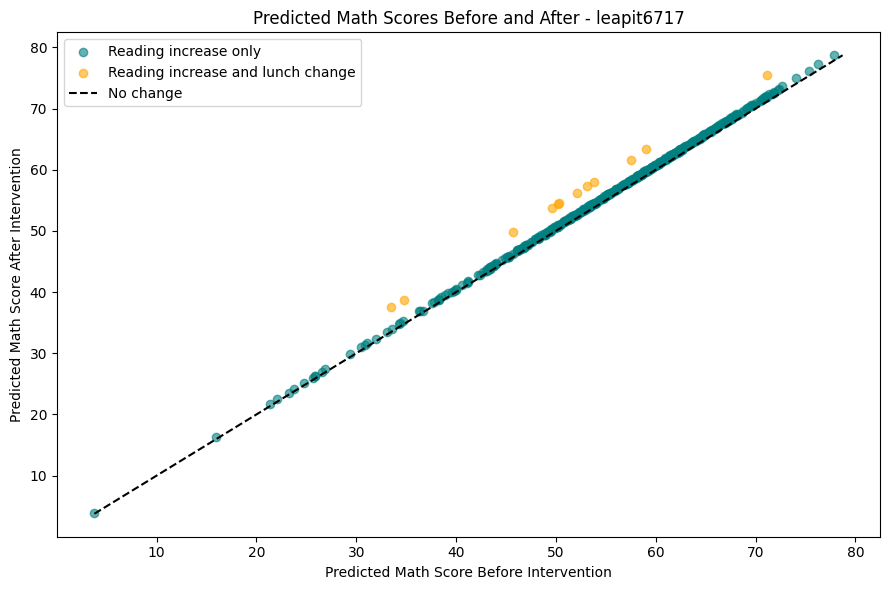

In [13]:
plt.figure(figsize=(9, 6))

for changed, label, color in [
    (False, "Reading increase only", "teal"),
    (True, "Reading increase and lunch change", "orange")
]:
    group = results.loc[
        results["Lunch Changed"] == changed
    ]

    plt.scatter(
        group["Before"],
        group["After"],
        color=color,
        alpha=0.6,
        label=label
    )

lowest = min(
    results["Before"].min(),
    results["After"].min()
)

highest = max(
    results["Before"].max(),
    results["After"].max()
)

plt.plot(
    [lowest, highest],
    [lowest, highest],
    color="black",
    linestyle="--",
    label="No change"
)

plt.title(
    "Predicted Math Scores Before and After - leapit6717"
)
plt.xlabel("Predicted Math Score Before Intervention")
plt.ylabel("Predicted Math Score After Intervention")
plt.legend()
plt.tight_layout()
plt.show()